# **Problem Statement**


---

#### **Business Context**  
Understanding customer personality and behavior is pivotal for businesses to enhance customer satisfaction and increase revenue. Segmentation based on a customer's personality, demographics, and purchasing behavior allows companies to create tailored marketing campaigns, improve customer retention, and optimize product offerings.  

A leading retail company with a rapidly growing customer base seeks to gain deeper insights into their customers' profiles. The company recognizes that understanding customer personalities, lifestyles, and purchasing habits can unlock significant opportunities for personalizing marketing strategies and creating loyalty programs. These insights can help address critical business challenges, such as improving the effectiveness of marketing campaigns, identifying high-value customer groups, and fostering long-term relationships with customers.  

With the competition intensifying in the retail space, moving away from generic strategies to more targeted and personalized approaches is essential for sustaining a competitive edge.  

---

#### **Objective**  
In an effort to optimize marketing efficiency and enhance customer experience, the company has embarked on a mission to identify distinct customer segments. By understanding the characteristics, preferences, and behaviors of each group, the company aims to:  
1. Develop personalized marketing campaigns to increase conversion rates.  
2. Create effective retention strategies for high-value customers.  
3. Optimize resource allocation, such as inventory management, pricing strategies, and store layouts.  

As a data scientist tasked with this project, your responsibility is to analyze the given customer data, apply machine learning techniques to segment the customer base, and provide actionable insights into the characteristics of each segment.  

---

#### **Data Dictionary**  
The dataset includes historical data on customer demographics, personality traits, and purchasing behaviors. Key attributes are:  

1. **Customer Information**  
   - **ID:** Unique identifier for each customer.  
   - **Year_Birth:** Customer's year of birth.  
   - **Education:** Education level of the customer.  
   - **Marital_Status:** Marital status of the customer.  
   - **Income:** Yearly household income (in dollars).  
   - **Kidhome:** Number of children in the household.  
   - **Teenhome:** Number of teenagers in the household.  
   - **Dt_Customer:** Date when the customer enrolled with the company.  
   - **Recency:** Number of days since the customer’s last purchase.  
   - **Complain:** Whether the customer complained in the last 2 years (1 for yes, 0 for no).  

2. **Spending Information (Last 2 Years)**  
   - **MntWines:** Amount spent on wine.  
   - **MntFruits:** Amount spent on fruits.  
   - **MntMeatProducts:** Amount spent on meat.  
   - **MntFishProducts:** Amount spent on fish.  
   - **MntSweetProducts:** Amount spent on sweets.  
   - **MntGoldProds:** Amount spent on gold products.  

3. **Purchase and Campaign Interaction**  
   - **NumDealsPurchases:** Number of purchases made using a discount.  
   - **AcceptedCmp1:** Response to the 1st campaign (1 for yes, 0 for no).  
   - **AcceptedCmp2:** Response to the 2nd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp3:** Response to the 3rd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp4:** Response to the 4th campaign (1 for yes, 0 for no).  
   - **AcceptedCmp5:** Response to the 5th campaign (1 for yes, 0 for no).  
   - **Response:** Response to the last campaign (1 for yes, 0 for no).  

4. **Shopping Behavior**  
   - **NumWebPurchases:** Number of purchases made through the company’s website.  
   - **NumCatalogPurchases:** Number of purchases made using catalogs.  
   - **NumStorePurchases:** Number of purchases made directly in stores.  
   - **NumWebVisitsMonth:** Number of visits to the company’s website in the last month.  

# **Let's start coding!**

## **Importing necessary libraries**

In [1]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to compute distances
from scipy.spatial.distance import cdist, pdist

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to visualize the elbow curve and silhouette scores
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## **Loading the data**

In [2]:
#run the following line if using Google Colab
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


## **Data Overview**

#### **Question 1**: What are the data types of all the columns?

In [3]:
# Load the data set
df = pd.read_csv("/content/drive/MyDrive/Customer_Personality_Segmentation.csv", sep='\t')

# Show the data type of all columns
print(df.dtypes)

ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object


##### **Observations:**
* The dataset contains a mix of numerical and categorical variables
* Some columns may require conversion to more appropriate data types to improve analysis accuracy and efficiency
* Columns such as complain and response appear to use integer values which makes them suitable for classification analysis

#### **Question 2:** Check the statistical summary of the data. What is the average household income?

In [4]:
print(df['Income'].describe())

count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
25%       35303.000000
50%       51381.500000
75%       68522.000000
max      666666.000000
Name: Income, dtype: float64


In [5]:
# Mean income in $ rounded to the nearest cent
print(f"${df['Income'].mean():.2f}")

$52247.25


##### **Observations:**



* The average household income is
about 52,247 dollars, indicating that most customers would fall within the middle-income range
* The median income, 51,381.50 dollars, is very close to the mean, suggesting the overall income distribution is relatively balanced
* The large standard deviation, 25,173 dollars, shows there is significant variation in customer income levels, meaning the dataset contains a diverse range of household
* Since incomes range widely, businesses could use income to create different marketing strategies, such as discounts for lower-income customers and premium offers for higher-income customers
* The maximum income of 666,666 dollars is extremely high compared to the rest of the data and is an outlier affecting statistical calculations. Given that the 75th percentile income is only 68,522 and the median is approximately 51,382, this unusually high value may represent a data entry error or an anomaly. Because outliers can disproportionately influence statistical measures such as the mean and standard deviation, this value should be further investigated or possibly even thrown out entirely before conducting predictive modeling or business analysis


#### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method

In [6]:
# Check for columns with missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

Income    24
dtype: int64


In [7]:
# Treat the missing values
df['Income'].fillna(df['Income'].median(), inplace=True)

In [8]:
# Verify the missing values were removed
print(df.isnull().sum())

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64


##### **Observations:**
The dataset contained missing values in the Income column. These missing values were treated using median imputation because the income data contains extreme outliers that could distort the mean. Using the median provides a more robust and reliable estimate for replacing missing values.

In this case, missing income values should be imputed rather than left blank because incomplete data can negatively affect statistical analysis and predictive modeling.

#### **Question 4**: Are there any duplicates in the data?

In [9]:
# Are there duplicates?
print(df.duplicated().sum())

0


##### **Observations:**
* The dataset does not contain any fully duplicated rows, meaning each customer record appears to be unique
* This absence of duplicates indicates good data quality and reduces the risk of biased/misleading model predictions
* Since there are no duplicates, no duplicate removal steps are necessary
* The unique records suggests the dataset was likely cleaned/well-maintained before analysis which also increases the confidence in the reliability of customer behavior and purchasing analyses performed on the dataset

## **Exploratory Data Analysis**

### Univariate Analysis


#### **Question 5:** Explore all the variables and provide observations on their distributions. (histograms and boxplots)

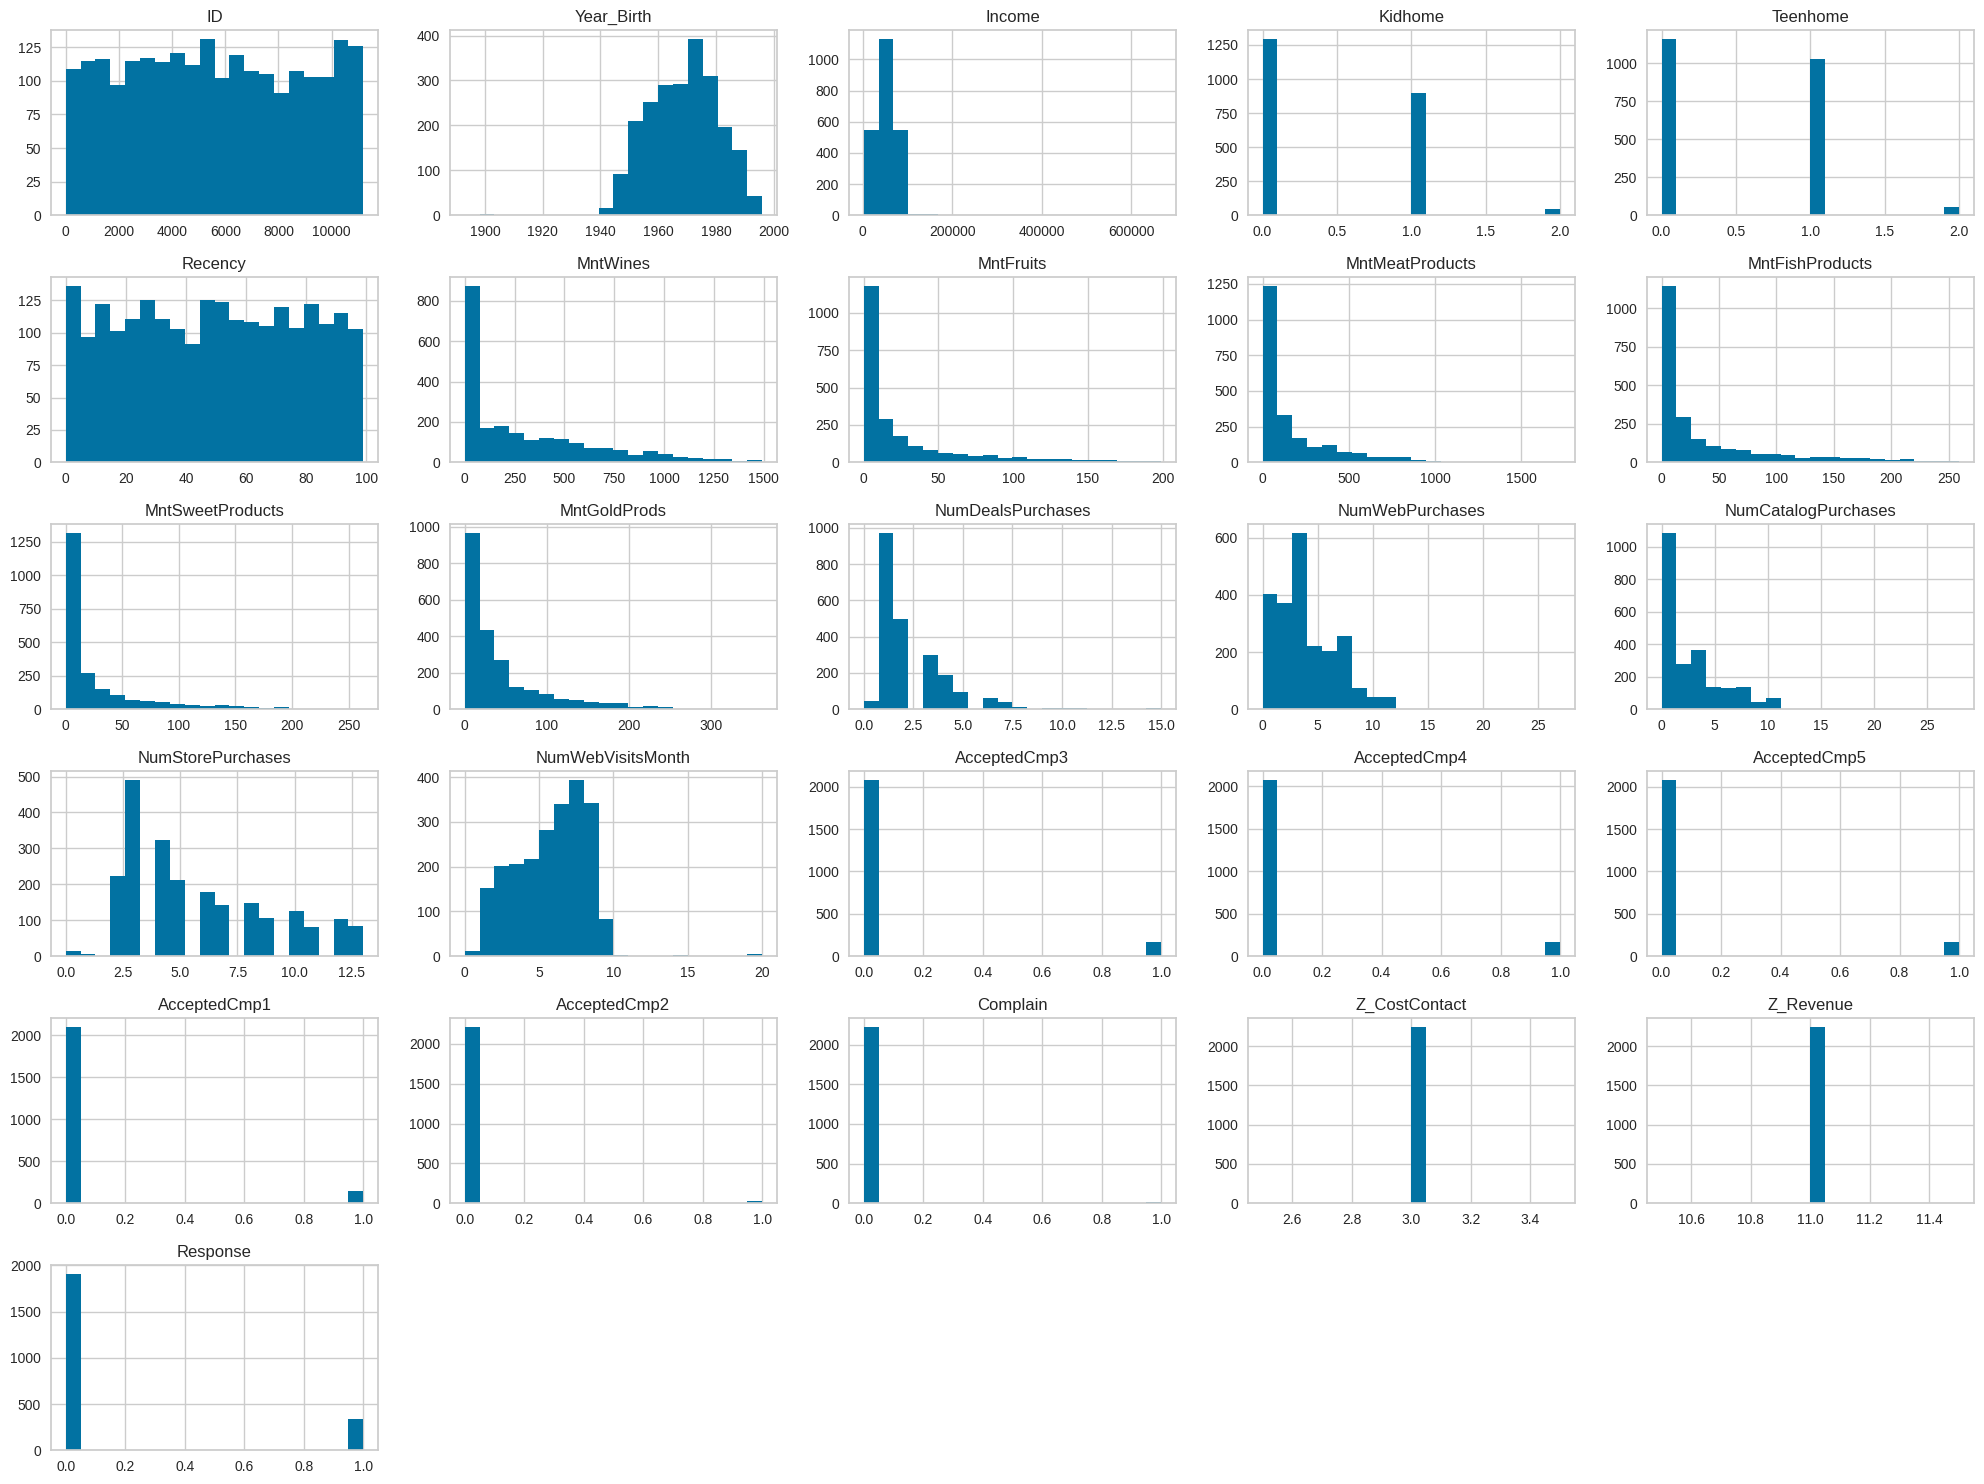

In [10]:
# Histogram
# Select numerical columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Configuration
df[numeric_cols].hist(figsize=(20, 15), bins=20)

plt.tight_layout()
plt.show()

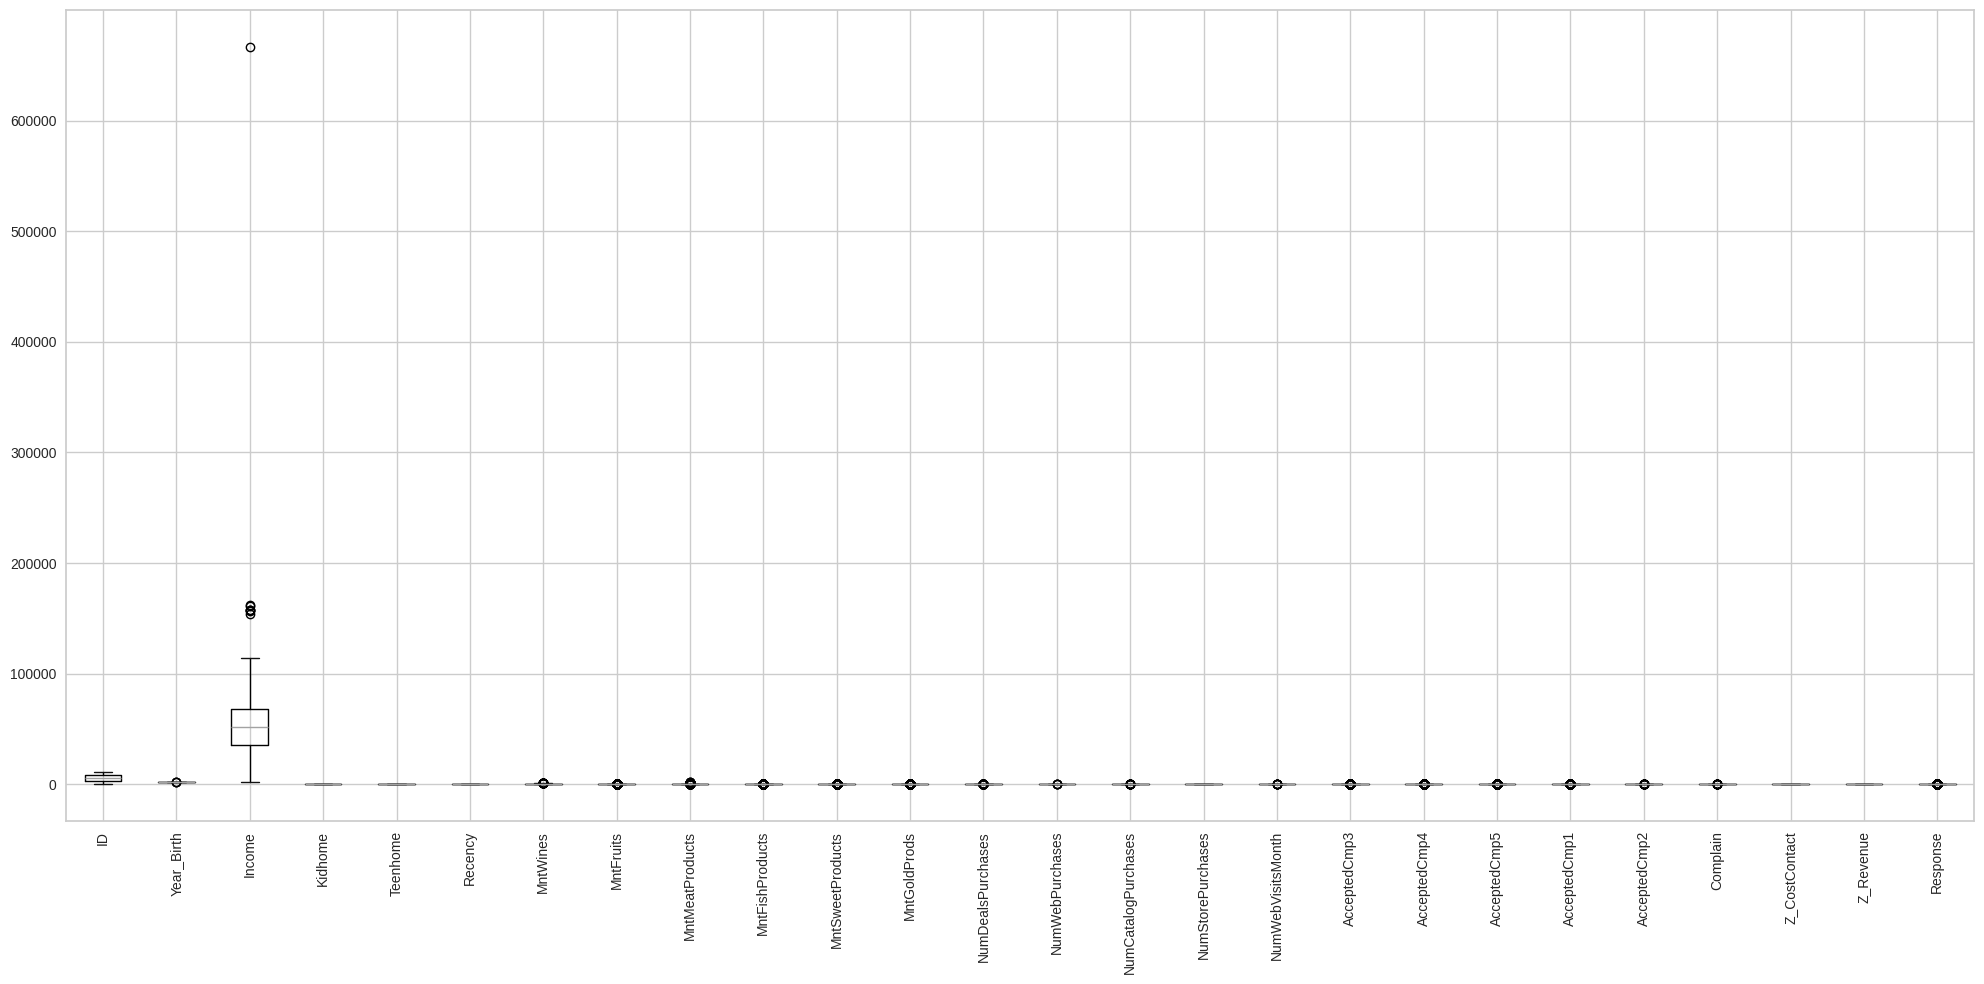

In [11]:
# Boxplot
plt.figure(figsize=(20, 10))

df[numeric_cols].boxplot(rot=90)

plt.tight_layout()
plt.show()

##### **Observations:**
* Many spending-related variables such as MntWines and MntMeatProducts are right-skewed, meaning most customers spend smaller amounts
* Several variables contain outliers, especially Income and product spending columns
* Purchase-related variables like NumWebPurchases, NumStorePurchases, etc. are concentrated around lower values, indicating most customers make relatively few purchases
* Removing the extreme outliers made the income and ID charts easier to interpret.

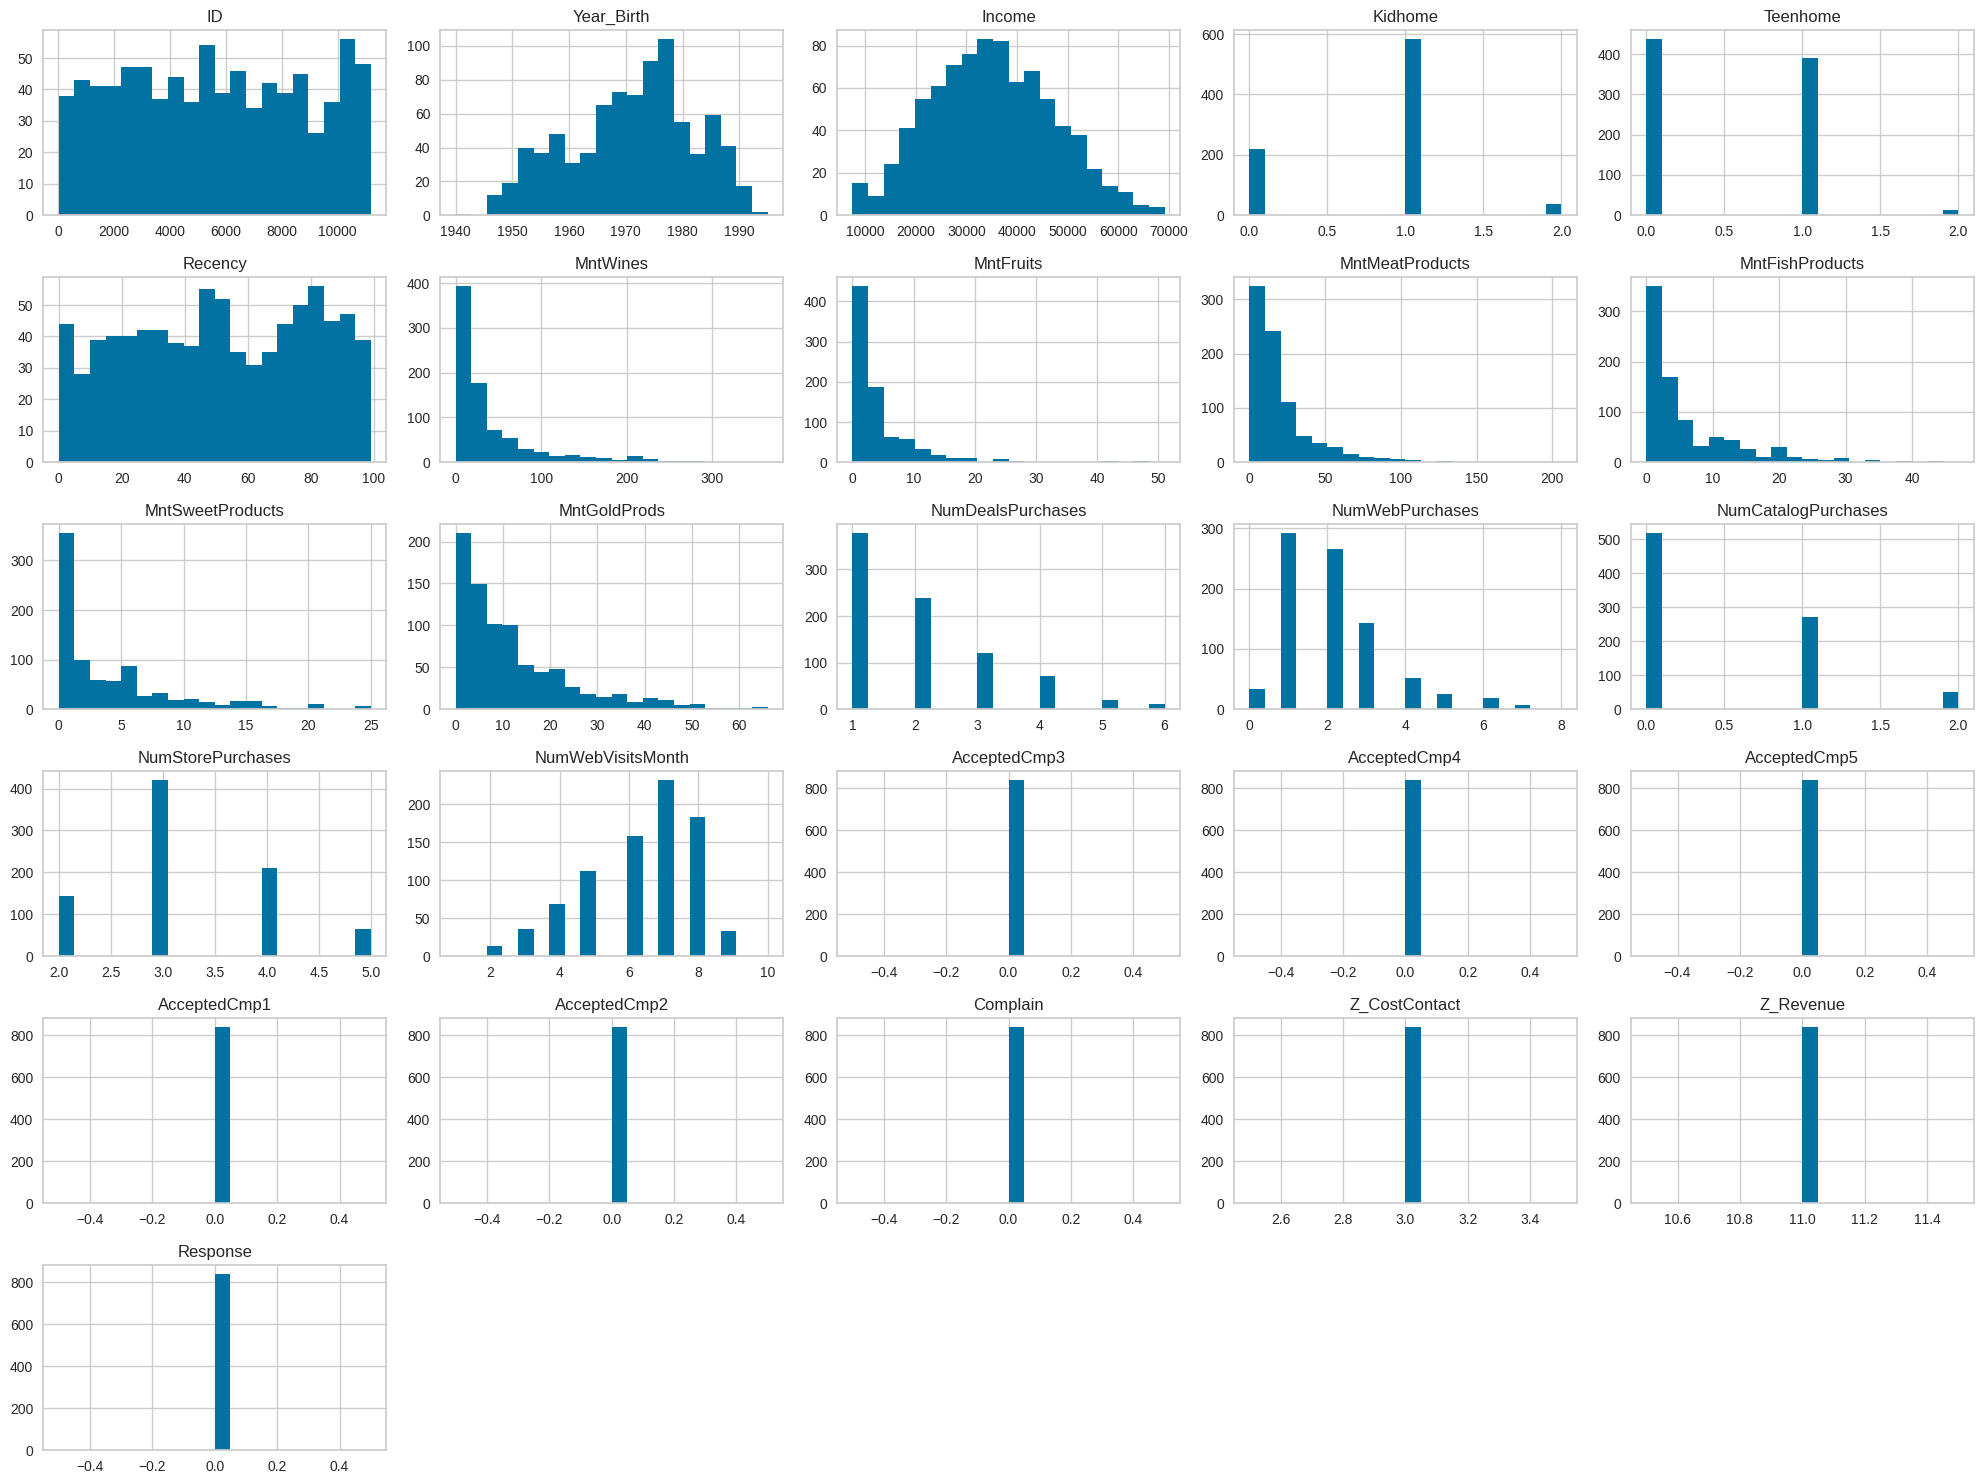

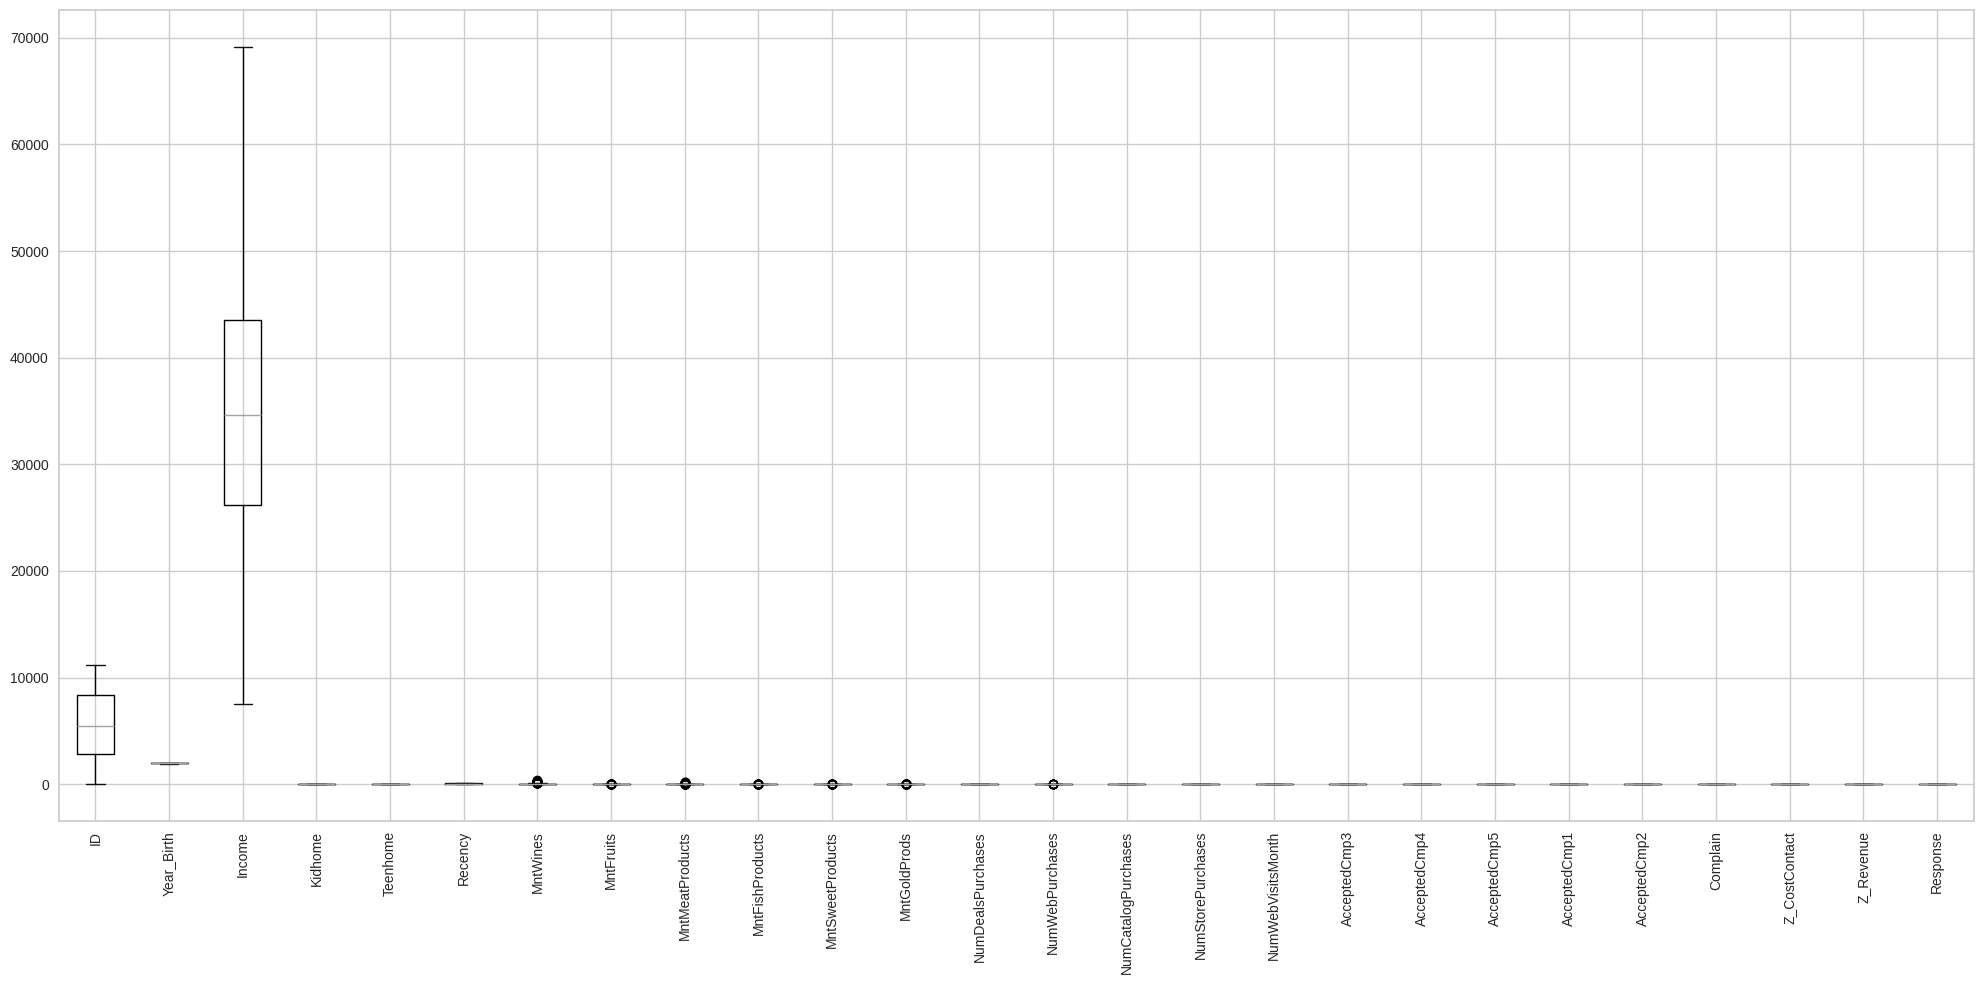

In [12]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Create a copy of the dataframe
df_no_outliers = df.copy()

# Remove outliers from all numerical columns using IQR
for col in numeric_cols:

    Q1 = df_no_outliers[col].quantile(0.25)
    Q3 = df_no_outliers[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_no_outliers = df_no_outliers[
        (df_no_outliers[col] >= lower_bound) &
        (df_no_outliers[col] <= upper_bound)
    ]

# Replot histograms without outliers
df_no_outliers[numeric_cols].hist(figsize=(20,15), bins=20)

plt.tight_layout()
plt.show()

# Replot boxplots without outliers
plt.figure(figsize=(20,10))

df_no_outliers[numeric_cols].boxplot(rot=90)

plt.tight_layout()
plt.show()

### Bivariate Analysis

#### **Question 6:** Perform multivariate analysis to explore the relationships between the variables.

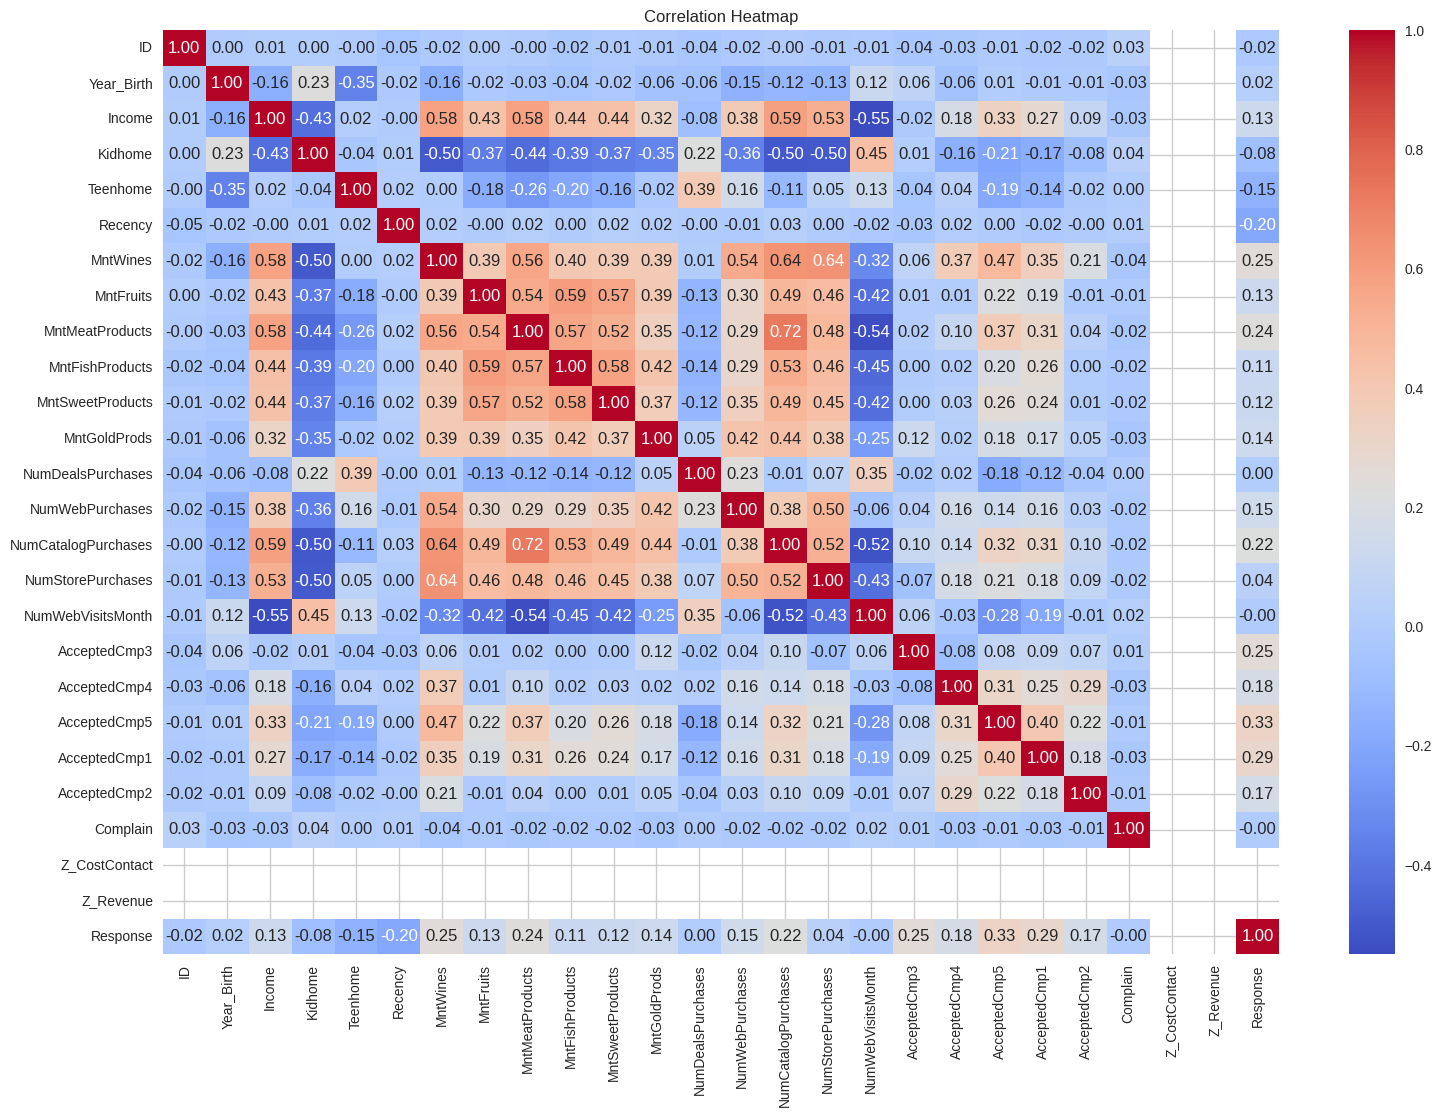

In [13]:
# Heatmap
# Select numerical columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Correlation matrix
corr_matrix = numeric_df.corr()

# Plot
plt.figure(figsize=(18,12))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

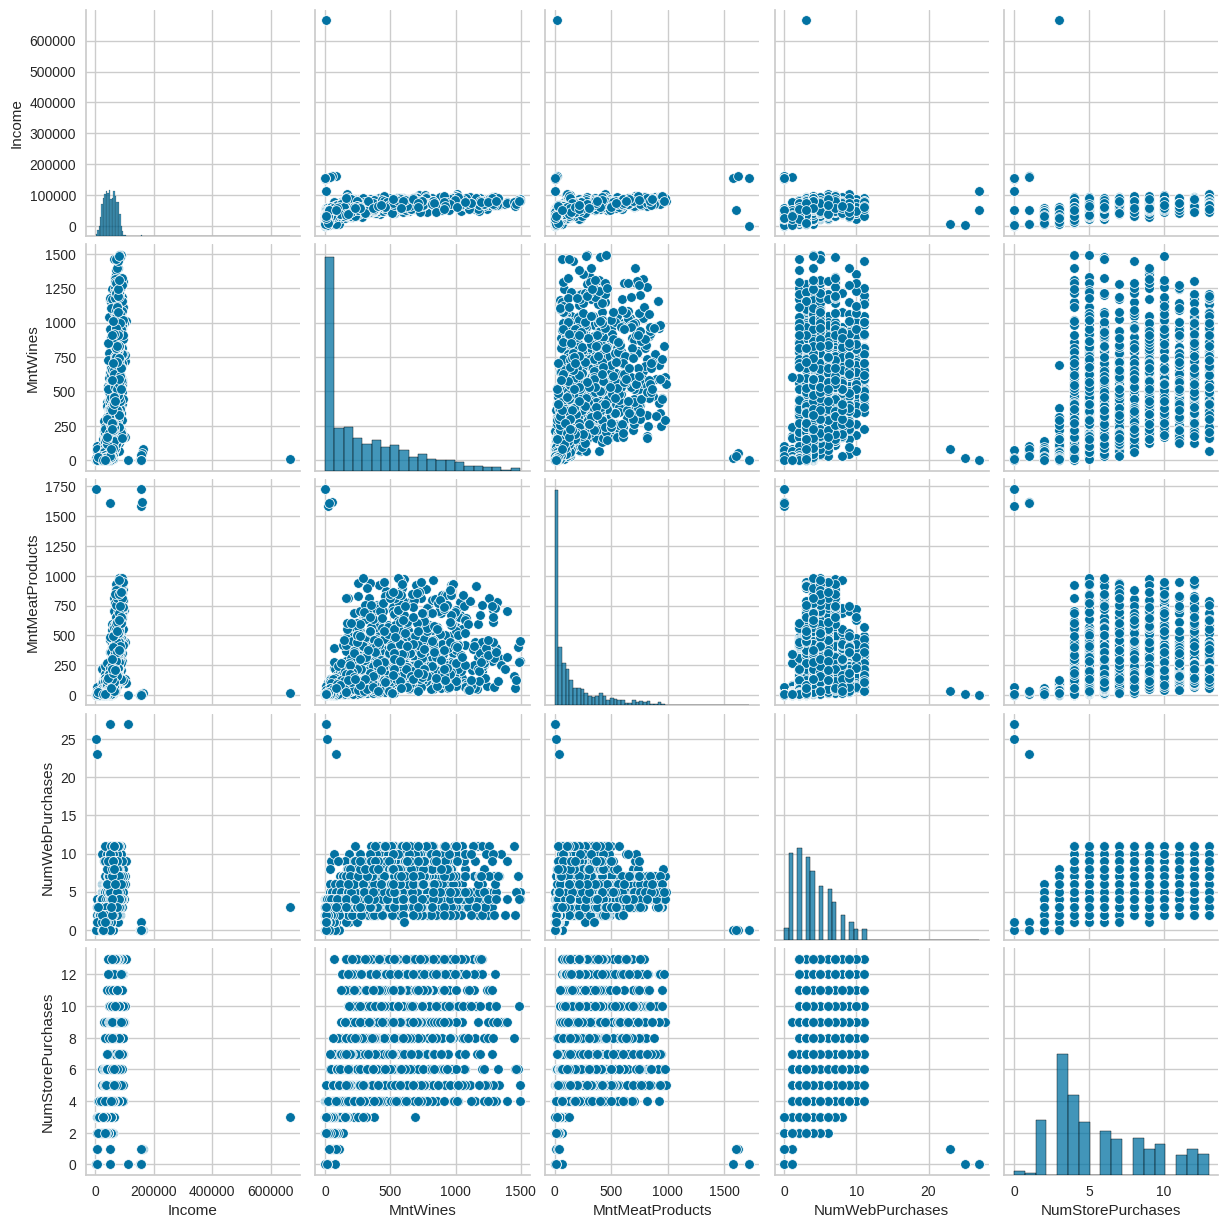

In [14]:
# Pairplot
selected_cols = ['Income', 'MntWines', 'MntMeatProducts',
                 'NumWebPurchases', 'NumStorePurchases']

sns.pairplot(df[selected_cols])

plt.show()

##### **Observations:**
* Overall, the heatmap seems to be the most effective of the charts because it clearly allows you to see the relationship between variables
* Income is often positively correlated with spending variables such as MntWines and MntMeatProducts, suggesting higher-income customers tend to spend more
* Spending variables are frequently correlated with one another, meaning that customers who spend heavily in one category often spend heavily in others
* NumWebPurchases, NumCatalogPurchases, and NumStorePurchases may show positive relationships, suggesting active customers tend to purchase through multiple channels
* NumWebVisitsMonth may show weaker or even negative relationships with purchases which could indicate some customers browse frequently without buying
* Marketing campaign acceptance variables, AcceptedCmp1-5 and Response may show relationships with customer spending and income, suggesting certain customer groups respond better to campaigns
* Correlation analysis helps identify which variables may be most useful for customer segmentation, predictive modeling, and targeting marketing strategies

## **K-means Clustering**

#### **Question 7** : Select the appropriate number of clusters using the elbow Plot. What do you think is the appropriate number of clusters?

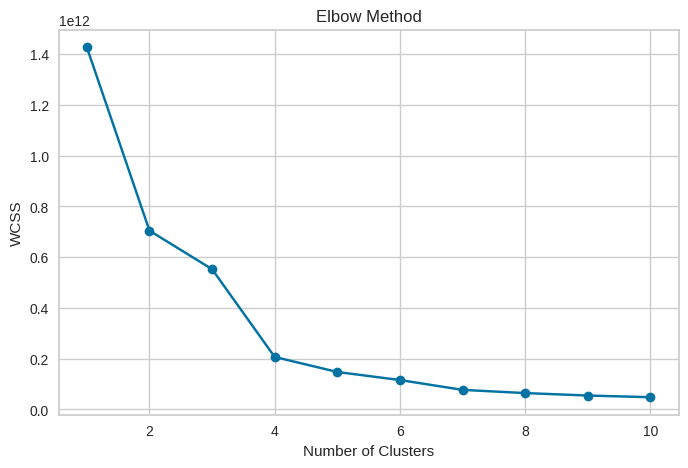

In [15]:
# Select numerical columns
X = df.select_dtypes(include=['int64', 'float64'])

# Store Within Cluster Sum of Squares values
wcss = []

# Test cluster sizes from 1 to 10
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.show()

##### **Observations:**
The elbow plot suggests that 4 clusters is likely the best choice because the rate of improvement slows noticeably after that point, meaning additional clusters would provide no meaningful benefit.

#### **Question 8** : finalize appropriate number of clusters by checking the silhouette score as well. Is the answer different from the elbow plot?

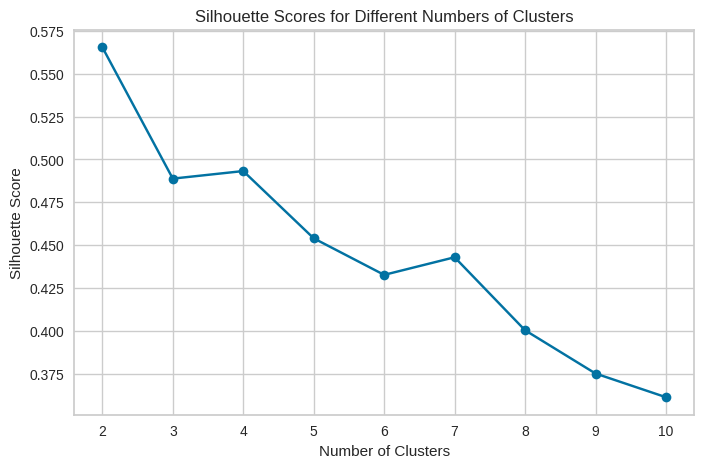

In [16]:
# Select numerical columns
X = df.select_dtypes(include=['int64', 'float64'])

silhouette_scores = []

# Test cluster sizes from 2 to 10
for i in range(2, 11):

    kmeans = KMeans(n_clusters=i, random_state=42)
    cluster_labels = kmeans.fit_predict(X)

    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)

# Plot silhouette scores
plt.figure(figsize=(8,5))

plt.plot(range(2,11), silhouette_scores, marker='o')

plt.title('Silhouette Scores for Different Numbers of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()

##### **Observations:**

The elbow plot and silhouette score produced different results because they evaluate clustering quality in different ways. The elbow method focuses on minimizing WCSS (within-cluster variation), which often favors adding more clusters to better fit the data. In contrast, the silhouette score measures how well-separated and distinct the clusters are from one another. In this case, the silhouette score suggests that 2 clusters create clearer and more distinct groupings, while the elbow plot suggests that 4 clusters may capture more detailed patterns within the data.

#### **Question 9**: Do a final fit with the appropriate number of clusters. How much total time does it take for the model to fit the data?

In [17]:
import time
# Select numerical columns
X = df.select_dtypes(include=['int64', 'float64'])

# Start timer
start_time = time.time()

# Fit K-means model
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X)

# End timer
end_time = time.time()

# Calculate total time
total_time = end_time - start_time

print(f"Total fit time: {total_time:.4f} seconds")

Total fit time: 0.0176 seconds


##### **Observations:**
* The K-means model fit the data very quickly, which shows that the algorithm is computationally efficient for datasets of this size. This short run time also suggests that K-means is practical for customer segmentation tasks such as this one, especially if we wanted to repeatedly update customer segments as new data becomes available.
* Since the dataset is relatively moderate in size, the model was able to identify cluster patterns almost instantly without requiring significant resources
* Although the model fit the data very quickly, selecting the appropriate number of clusters remains important to ensure the clusters were meaningful and interpretable. The silhouette score suggested 2 clusters, but a business analyst would likely choose 4 clusters because it provides a more detailed customer segmentation.


## **Cluster Profiling and Comparison**

#### **Question 10**: Perform cluster profiling using boxplots for the K-Means algorithm. Analyze key characteristics of each cluster and provide detailed observations.

In [18]:
#Fit the final K-means model & assign cluster labels

# Select numerical columns
X = df.select_dtypes(include=['int64', 'float64'])

# Fit K-means
kmeans = KMeans(n_clusters=4, random_state=42)

# Create cluster labels
df['Cluster'] = kmeans.fit_predict(X)

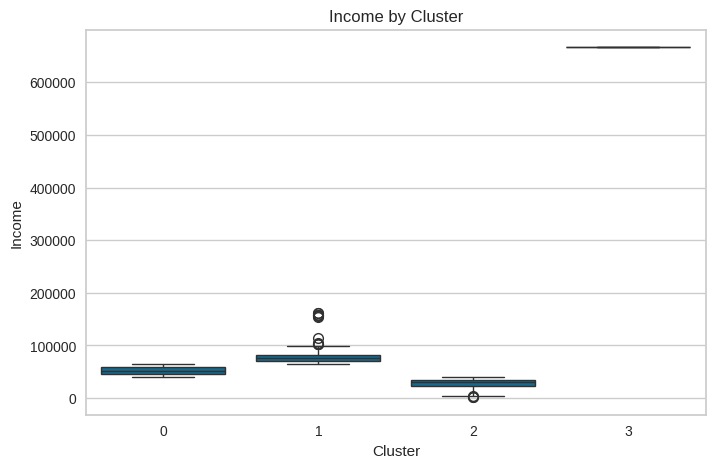

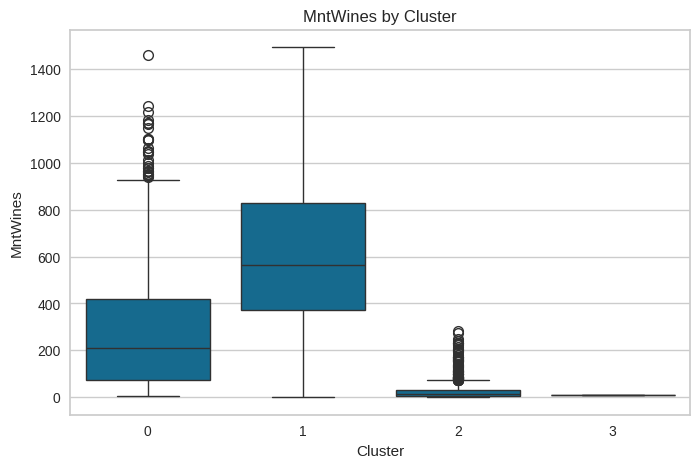

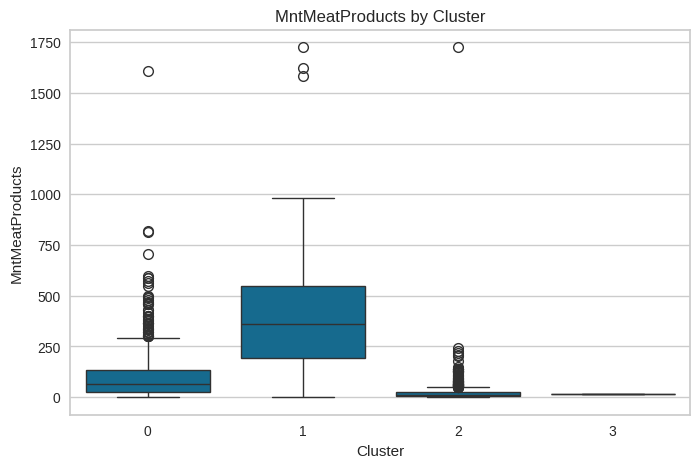

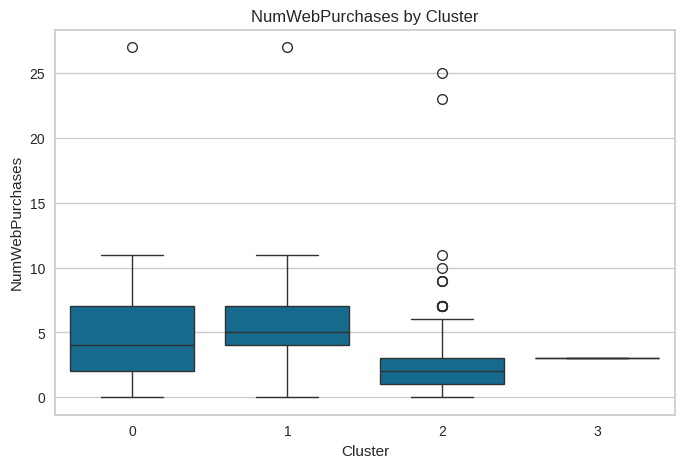

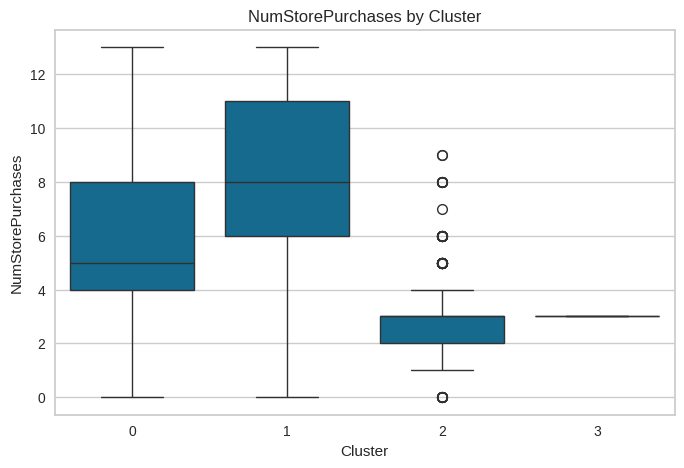

In [19]:
# Create the boxplot
# Variables to analyze
features = ['Income', 'MntWines', 'MntMeatProducts',
            'NumWebPurchases', 'NumStorePurchases']

# Create boxplots
for feature in features:

    plt.figure(figsize=(8,5))

    sns.boxplot(x='Cluster', y=feature, data=df)

    plt.title(f'{feature} by Cluster')

    plt.show()

##### **Observations:**
* Income appears strongly related to customer spending behavior, as higher-income clusters generally spend more on products.
* Cluster 1 represents the most valuable customer segment because of its high income and high purchasing activity.
* Cluster 2 represents lower-value or budget-conscious customers with lower purchasing behavior.
* The presence of the extreme outlier heavily influenced Cluster 3 and may have affected the clustering results overall.
* K-means clustering successfully separated customers into groups with distinct spending and purchasing patterns that could be useful for targeted marketing strategies.

#### **Question 11**: Perform cluster profiling on the data using a barplot for the K-Means algorithm. Provide insights and key observations for each cluster based on the visual analysis.

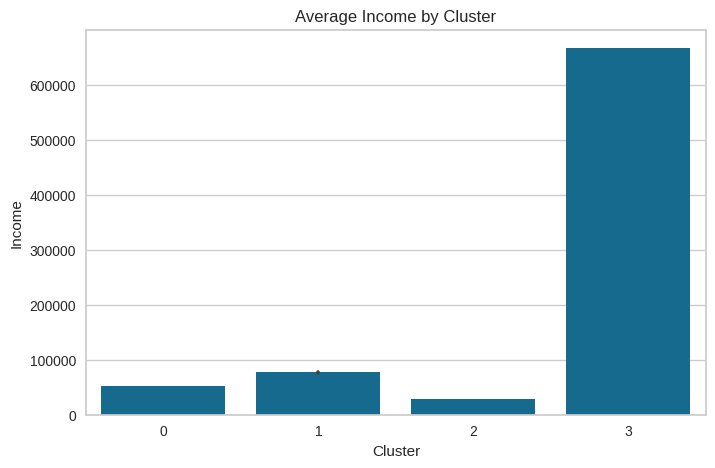

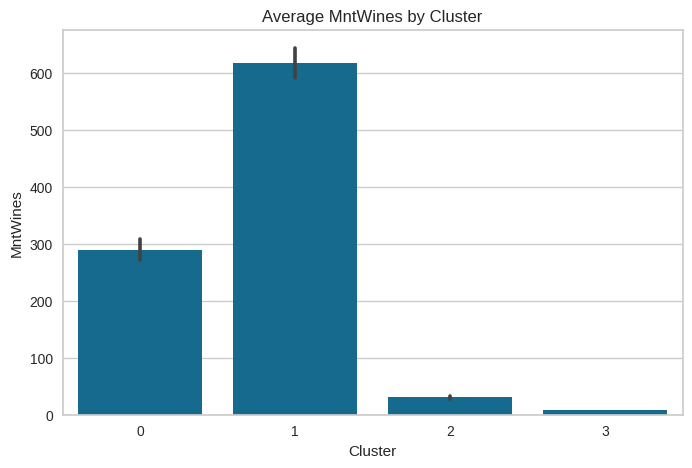

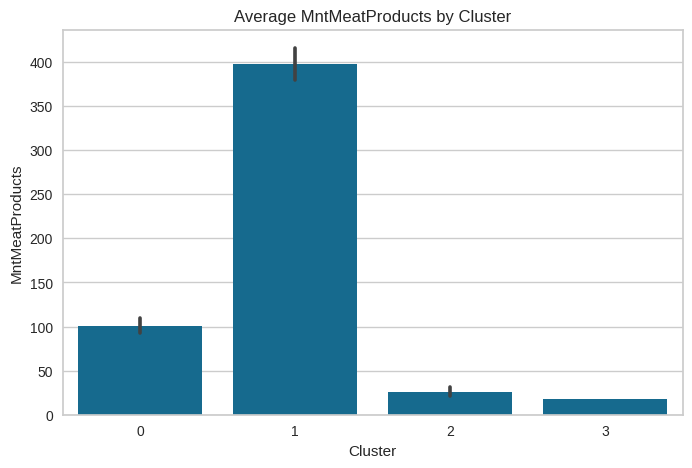

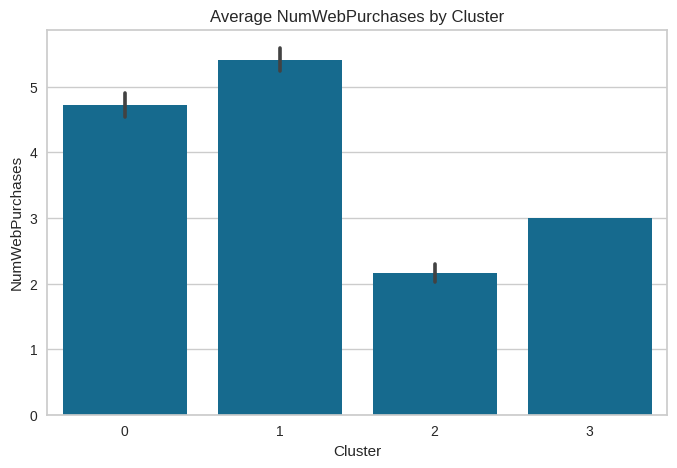

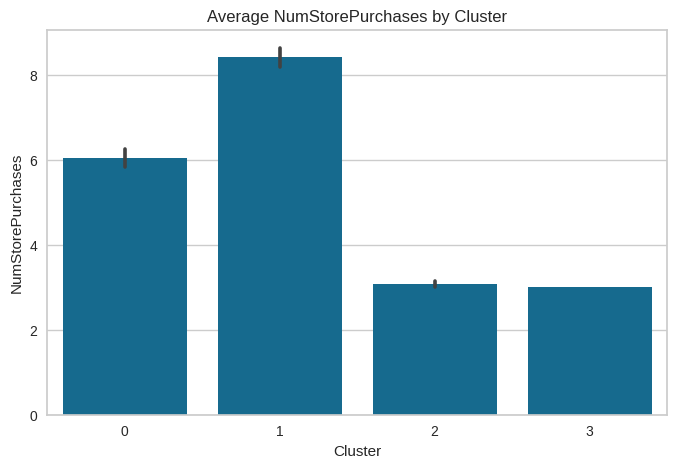

In [20]:
# Variables to analyze
features = ['Income', 'MntWines', 'MntMeatProducts',
            'NumWebPurchases', 'NumStorePurchases']

# Create barplots
for feature in features:

    plt.figure(figsize=(8,5))

    sns.barplot(x='Cluster', y=feature, data=df)

    plt.title(f'Average {feature} by Cluster')

    plt.show()

##### **Observations:**
* Higher-income clusters generally spend more and make more purchases across multiple channels.
* Cluster 1 represents the most profitable and engaged customers.
* Cluster 2 represents lower-spending customers who may require different marketing strategies.
* The extreme outlier significantly influenced Cluster 3 and may have affected the clustering structure.
* The barplots clearly show meaningful differences in customer income, spending, and purchasing behavior across clusters, demonstrating that K-means successfully identified distinct customer segments.

## **Business Recommendations**

#### **Question 12**: Based on the cluster insights, what business recommendations can be provided?

## General Observations:
1. Businesses should create targeted marketing strategies for each customer segment rather than using the same approach for all customers.

2. Cluster 1, which contains the highest-income and highest-spending customers, should be prioritized for loyalty programs, premium products, personalized recommendations, and exclusive promotions because these customers contribute the most revenue.

3. Cluster 0 represents moderate-spending customers who may have the potential to become higher-value customers. Businesses could encourage increased spending through bundled offers, rewards programs, or personalized marketing campaigns.

4. Cluster 2 appears more budget-conscious with lower spending and purchasing activity. Discounts, coupons, and promotional campaigns may be most effective for attracting and retaining these customers.

5. The extreme outlier identified in Cluster 3 should be investigated further because it may represent a data entry error or an unusual customer profile. Removing or correcting the outlier could improve future clustering results. Cluster 3 may disappear entirely or merge with another cluster since it appears to have been created mainly because of the extreme income outlier.

6. Since spending behavior differs significantly across clusters, businesses can improve customer engagement and profitability by using customer segmentation to support targeted advertising, product recommendations, and retention strategies.

7. The analysis suggests that income is strongly related to spending behavior, so businesses may benefit from tailoring products and campaigns based on customer purchasing power.


# Removal of extreme income outlier:
If the extreme outlier in Cluster 3 were removed, several parts of the analysis would change noticeably. Here are some specific examples based on recomputed data that excludes the extreme income outlier:

The average income would decrease slightly:
Before removing outliers: 52,237.98
After removing outliers: 51,630.93

The standard deviation would decrease significantly:
Before: 25,037.96
After: 20,601.68

The maximum income changed dramatically:
Before: 666,666
After: 113,734

Overall, removing this outlier would do the following:
* Cluster 3 would likely disappear or become merged with another cluster because it appears that this cluster was formed mainly due to the extreme income outlier. The remaining clusters would likely become more balanced and realistic.
* High-income customers would still exist, but the model would focus more on actual customer behavior patterns rather than isolating one extreme observation.
* Visualizations such as boxplots would become easier to interpret because the scale would no longer be stretched by the extreme value.
* The clustering results themselves would improve because k-means relies heavily on distance calculations, and extreme outliers can strongly influence cluster centers.